In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import torch.backends.cudnn as cudnn
import torchvision
import torchvision.transforms as transforms
import os
import argparse
from pathlib import Path
import re
import random
import math
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, roc_auc_score, classification_report, confusion_matrix
from torch.utils.data import Dataset, DataLoader
import pandas as pd
# for CSDI:
!pip install -q linear-attention-transformer
!wget -q https://raw.githubusercontent.com/ermongroup/CSDI/main/diff_models.py -O diff_models.py

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
! pip install pycwt

In [ ]:
import sys
my_path = '/content/drive/MyDrive/aim3/codes/1080_30min/WTC/'
sys.path.append(my_path)

### Model initialization

In [ ]:
from models import ChannelAwareNAOMI
MODEL_KWARGS = dict(data_dim=2,hidden_dim=64,decoder_hidden=128,
                    highest=16,rnn_layers=1,normalize=True)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
best_model=ChannelAwareNAOMI(**MODEL_KWARGS).to(DEVICE)

In [ ]:
GAP_NPZ = "/content/drive/MyDrive/aim3/artificial_gaps_36segments_100seeds.npz" # 36 12-hour segment path (constant)
GT_WTC_NPZ = "/content/drive/MyDrive/aim3/wtc_maps_12h_windows_only.npz" # ground truth path (constant)
MODEL_OUT_DIR = '/content/drive/MyDrive/aim3/NAOMI_ChannelAware_5fold_1e-3_64' # need to be changed!
CKPT_DIR = os.path.join(MODEL_OUT_DIR, "ckpts")
FOLD_CSV = os.path.join(MODEL_OUT_DIR, "cv5_fold_results.csv")
OUT_DIR = "/content/drive/MyDrive/aim3/wtc_NAOMI_eval_100seeds_fullWTC_inCOI_chunk1080"

In [ ]:
fold_df = pd.read_csv(FOLD_CSV)
best_per_fold = (
    fold_df.groupby("fold", as_index=False)
    .agg(
        val_overall_mae=("val_overall_mae", "first"),
        best_epoch=("best_epoch", "first"),
    )
    .sort_values("val_overall_mae", ascending=True)
    .reset_index(drop=True)
)

# Select best fold based on validation MAE
best_row = best_per_fold.iloc[0]

best_fold = int(best_row["fold"])
best_val_mae = float(best_row["val_overall_mae"])
best_epoch = int(best_row["best_epoch"])

# Locate checkpoint
best_ckpt_path = os.path.join(
    CKPT_DIR,
    f"fold{best_fold:02d}_best.pt"
)

print("\nBest fold selected:")
print("  fold         :", best_fold)
print("  val MAE      :", best_val_mae)
print("  best epoch   :", best_epoch)
print("  checkpoint   :", best_ckpt_path)

# Load trained weights
state = torch.load(
    best_ckpt_path,
    map_location=DEVICE,
    weights_only=True
)

best_model.load_state_dict(state)
best_model.eval()

print("Best NAOMI model loaded successfully.")


Best fold selected:
  fold         : 4
  val MAE      : 1.106230987743496
  best epoch   : 14
  checkpoint   : /content/drive/MyDrive/aim3/NAOMI_ChannelAware_5fold_1e-3_64/ckpts/fold04_best.pt
Best NAOMI model loaded successfully.


### WTC

Device=cpu | seeds=100 | segments=36 | valid GT=36
Saved shared COI pixel index: /content/drive/MyDrive/aim3/wtc_NAOMI_eval_100seeds_fullWTC_inCOI_chunk1080/naomi_wtc_log_terms_pixel_index.npz


Ground-truth N/A/B (once):   0%|          | 0/36 [00:00<?, ?it/s]

NAOMI WTC + log-term evaluation:   0%|          | 0/100 [00:00<?, ?it/s]


Overall metrics and log-term mean absolute magnitudes:
full_wtc_coi_mae               7.784029e-02
full_wtc_coi_mape              2.067806e+06
full_wtc_coi_ssim              7.699672e-01
full_wtc_coi_iou_pct_thr0p5    7.313749e+01
E_N_mean_abs                   7.628409e-01
E_A_mean_abs                   3.870787e-01
E_B_mean_abs                   1.679858e-01
E_den_mean_abs                 5.189356e-01
dtype: float64


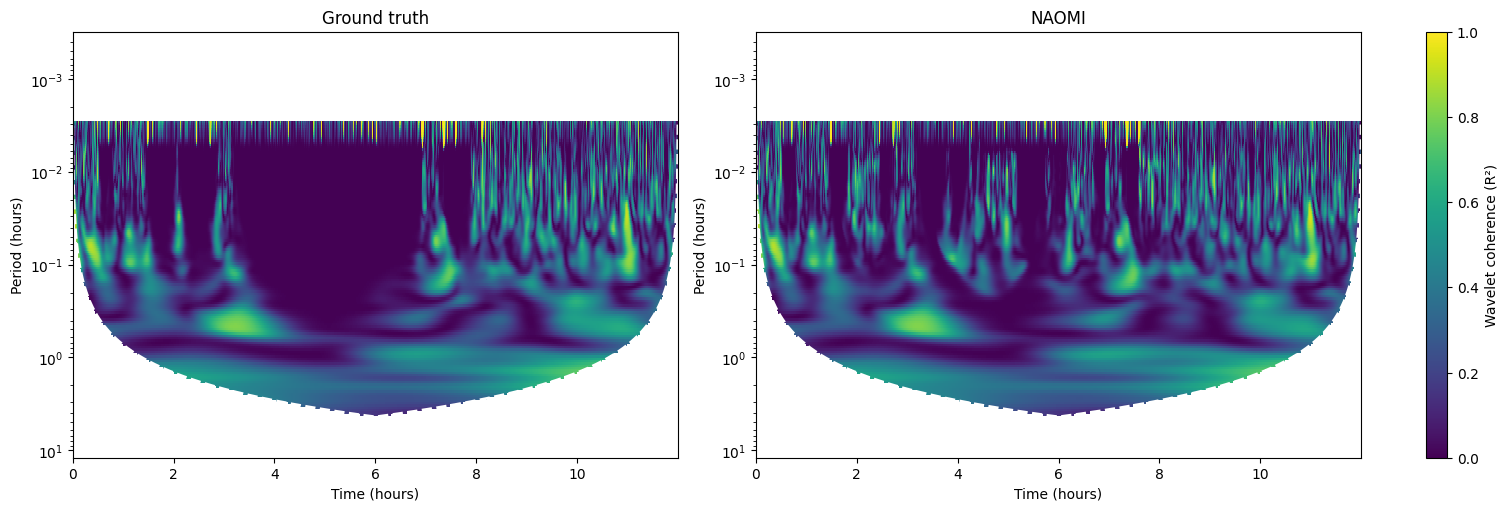


Highest MAPE example:
 seed_index                                                                          56
seed                                                                              1393
segment_idx_original                                                                29
segment_idx_valid_order                                                             29
patient_id                                                                     patient
filename                                patient_58_12h_window_002_rows_14566-23205.csv
n_valid_pixels_in_coi                                                           951418
full_wtc_coi_mae                                                              0.054486
full_wtc_coi_mape                                                      122356706.01463
full_wtc_coi_ssim                                                             0.783468
full_wtc_coi_iou_pct_thr0p5                                                  69.998703
full_wtc_coi_iou_in

In [ ]:
"""Evaluate an ALREADY LOADED ChannelAwareNAOMI and save WTC log components.

Requires existing notebook variables:
    best_model: initialized, trained checkpoint already loaded
    GAP_NPZ, GT_WTC_NPZ, OUT_DIR: defined paths

Saves:
    * Original full-WTC-in-COI metrics (CSV) and per-seed summary (CSV)
    * Three separate pixelwise log-ratio terms E_N, E_A, E_B (one NPZ per seed)
    * Shared COI pixel index needed to reconstruct each (scales, time) map
    * Per-segment and per-seed statistics of each log term
    * Worst-MAPE WTC pair, log-term maps and PNG

NOTE: E_N - E_A - E_B = log(R_model^2 / R_GT^2), for positive N/A/B.
      The COI-pixel NPZ files avoid storing huge out-of-COI arrays.
"""
import os
import numpy as np
import pandas as pd
import torch
import pycwt as wavelet
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from skimage.metrics import structural_similarity as ssim

DT, DJ, S0 = 5.0, 1 / 12, 10.0
CHUNK_LEN, BATCH_SIZE = 1080, 64
EPS, IOU_THRESHOLD = 1e-8, 0.5
os.makedirs(OUT_DIR, exist_ok=True)
best_model.eval()
DEVICE = next(best_model.parameters()).device
mother = wavelet.Morlet(6)


def wtc_metrics(gt, pred, mask):
    """Preserve the original MAE/MAPE/SSIM/IoU definitions."""
    if not mask.any():
        return np.nan, np.nan, np.nan, np.nan, 0, 0
    a = gt[mask].astype(np.float64)
    b = pred[mask].astype(np.float64)
    mae = float(np.mean(np.abs(a - b)))
    mape = float(100 * np.mean(np.abs(a - b) / np.maximum(np.abs(a), EPS)))
    rr, cc = np.where(mask)
    rs, cs = slice(rr.min(), rr.max() + 1), slice(cc.min(), cc.max() + 1)
    gt_crop = np.where(mask[rs, cs], gt[rs, cs], 0).astype(np.float32)
    pr_crop = np.where(mask[rs, cs], pred[rs, cs], 0).astype(np.float32)
    similarity = (float(ssim(gt_crop, pr_crop, data_range=1.0))
                  if min(gt_crop.shape) >= 7 else np.nan)
    g = (gt > IOU_THRESHOLD) & mask
    p = (pred > IOU_THRESHOLD) & mask
    intersection = int(np.count_nonzero(g & p))
    union = int(np.count_nonzero(g | p))
    return mae, mape, similarity, (100 * intersection / union if union else np.nan), intersection, union


@torch.no_grad()
def impute_chunks(x, observed_mask):
    """Run NAOMI on separate 1080-point chunks, rejoin each 12-hour series."""
    n, t, d = x.shape
    if d != 2 or t % CHUNK_LEN:
        raise ValueError(f"Expected (N, multiple of {CHUNK_LEN}, 2), got {x.shape}")
    xs = np.nan_to_num(x, nan=0, posinf=0, neginf=0).reshape(-1, CHUNK_LEN, d)
    ms = observed_mask.reshape(-1, CHUNK_LEN, d)
    outputs = []
    for start in range(0, len(xs), BATCH_SIZE):
        xb = torch.as_tensor(xs[start:start+BATCH_SIZE], dtype=torch.float32, device=DEVICE)
        mb = torch.as_tensor(ms[start:start+BATCH_SIZE], dtype=torch.float32, device=DEVICE)
        outputs.append(best_model(xb, mb)["x_c"].cpu().numpy())
    return np.concatenate(outputs, axis=0).reshape(n, t, d)


def wtc_components(x, y, J):
    """Reproduce pycwt.wct(sig=False) while exposing N, A, B (float64).

    pycwt.wct defaults to normalize=True, so standardize each entire
    12-hour channel before its CWT. Return squared coherence R2=N/(A*B).
    """
    x = np.asarray(x, dtype=np.float64)
    y = np.asarray(y, dtype=np.float64)
    sx, sy = x.std(), y.std()
    if (not np.isfinite(x).all() or not np.isfinite(y).all()
            or not np.isfinite(sx) or not np.isfinite(sy) or sx == 0 or sy == 0):
        raise ValueError("WTC component computation requires finite, nonconstant signals")
    x, y = (x - x.mean()) / sx, (y - y.mean()) / sy
    W1, scales, _, coi, _, _ = wavelet.cwt(x, dt=DT, dj=DJ, s0=S0, J=J, wavelet=mother)
    W2, _, _, _, _, _ = wavelet.cwt(y, dt=DT, dj=DJ, s0=S0, J=J, wavelet=mother)
    inv_scales = 1.0 / scales[:, None]
    A = mother.smooth(np.abs(W1)**2 * inv_scales, DT, DJ, scales)
    B = mother.smooth(np.abs(W2)**2 * inv_scales, DT, DJ, scales)
    S12 = mother.smooth(W1 * W2.conj() * inv_scales, DT, DJ, scales)
    N = np.abs(S12)**2
    with np.errstate(divide="ignore", invalid="ignore"):
        R2 = N / (A * B)
    return R2, coi, N, A, B


def stats_for_log_terms(en, ea, eb):
    """Summarize signed and absolute log effects using common valid pixels."""
    good = np.isfinite(en) & np.isfinite(ea) & np.isfinite(eb)
    out = {"n_log_valid_pixels": int(good.sum())}
    if not good.any():
        for name in ("E_N", "E_A", "E_B", "E_den", "E_logR2"):
            out[name + "_mean"] = np.nan
            out[name + "_mean_abs"] = np.nan
        return out
    terms = {
        "E_N": en[good], "E_A": ea[good], "E_B": eb[good],
        "E_den": ea[good] + eb[good],
        "E_logR2": en[good] - ea[good] - eb[good],
    }
    for name, z in terms.items():
        out[name + "_mean"] = float(z.mean())
        out[name + "_mean_abs"] = float(np.abs(z).mean())
    return out


# --------------------------------------------------------------------
# Load original clean and artificially gapped 12-hour signals
# --------------------------------------------------------------------
with np.load(GAP_NPZ, allow_pickle=True) as data:
    X_clean = data["X"].astype(np.float32)       # Needed for GT N,A,B
    X_gapped = data["X_in"].astype(np.float32)   # (S,N,T,2)
    M_hat = data["M_hat"].astype(np.float32)
    seed_values = data["seed_values"]
    patient_ids = data["patient_ids"]
    filenames = data["filenames"].astype(str)

S, NSEG, T, D = X_gapped.shape
assert D == 2 and X_clean.shape == (NSEG, T, D)
assert M_hat.shape == X_gapped.shape and T % CHUNK_LEN == 0
assert len(seed_values) == S and len(patient_ids) == NSEG

with np.load(GT_WTC_NPZ, allow_pickle=True) as data:
    gt_wtc = data["wtc_full"].astype(np.float32)
    gt_coi = data["coi_sec"].astype(np.float32)
    saved_periods = data["periods_full_sec"].astype(np.float64)

J = int(np.floor(np.log2(T * DT / S0) / DJ))
periods = S0 * 2 ** (np.arange(J + 1) * DJ) * mother.flambda()
F = len(periods)
assert gt_wtc.shape == (NSEG, F, T) and gt_coi.shape == (NSEG, T)
if not np.allclose(saved_periods, periods, rtol=1e-4, atol=1e-3):
    raise ValueError("Saved GT periods differ from the current wavelet settings")

valid_gt = (np.isfinite(gt_wtc).all(axis=(1, 2)) &
            (gt_wtc >= 0).all(axis=(1, 2)) &
            (gt_wtc <= 1).all(axis=(1, 2)) &
            np.isfinite(gt_coi).all(axis=1) &
            (gt_coi > 0).all(axis=1))
valid_idx = np.flatnonzero(valid_gt)
if not len(valid_idx):
    raise ValueError("No valid GT WTC segments")

# Fixed across seeds: COI index per valid segment, then concatenate.
coi_masks = [periods[:, None] <= gt_coi[i][None, :] for i in valid_idx]
flat_idx = [np.flatnonzero(m).astype(np.int32) for m in coi_masks]
offsets = np.r_[0, np.cumsum([len(z) for z in flat_idx])].astype(np.int64)
all_flat_idx = np.concatenate(flat_idx)
index_path = os.path.join(OUT_DIR, "naomi_wtc_log_terms_pixel_index.npz")
np.savez_compressed(index_path,
                    valid_idx=valid_idx, offsets=offsets,
                    flat_indices=all_flat_idx, map_shape=np.array([F, T]),
                    periods_sec=periods, coi_sec=gt_coi[valid_idx],
                    seed_values=seed_values)
print(f"Device={DEVICE} | seeds={S} | segments={NSEG} | valid GT={len(valid_idx)}")
print(f"Saved shared COI pixel index: {index_path}")

# --------------------------------------------------------------------
# Compute ground-truth log N, log A, log B ONCE (not for each seed).
# --------------------------------------------------------------------
gt_logs = []
for j, i in enumerate(tqdm(valid_idx, desc="Ground-truth N/A/B (once)")):
    R2gt, _, n_gt, a_gt, b_gt = wtc_components(X_clean[i, :, 0], X_clean[i, :, 1], J)
    mask = coi_masks[j]
    discrepancy = np.max(np.abs(np.clip(R2gt[mask], 0, 1) - gt_wtc[i][mask]))
    if not np.isfinite(discrepancy) or discrepancy > 5e-4:
        raise ValueError(f"GT WTC inconsistent with computed components for segment {i}: "
                         f"max |delta|={discrepancy:.6g}. Verify ordering/settings.")
    with np.errstate(divide="ignore", invalid="ignore"):
        gt_logs.append((np.log(n_gt[mask]), np.log(a_gt[mask]), np.log(b_gt[mask])))

# --------------------------------------------------------------------
# All seeds: use one CWT decomposition for both WTC metrics and E terms.
# --------------------------------------------------------------------
rows, worst = [], None
for s in tqdm(range(S), desc="NAOMI WTC + log-term evaluation"):
    completed = impute_chunks(X_gapped[s], M_hat[s])
    eN_all = np.full(offsets[-1], np.nan, dtype=np.float32)
    eA_all = np.full(offsets[-1], np.nan, dtype=np.float32)
    eB_all = np.full(offsets[-1], np.nan, dtype=np.float32)

    for j, i in enumerate(valid_idx):
        R2m, _, Nm, Am, Bm = wtc_components(completed[i, :, 0], completed[i, :, 1], J)
        # Match original evaluation: clip full WTC into [0,1] for MAE/MAPE/SSIM/IoU.
        pred = np.clip(np.nan_to_num(R2m, nan=0, posinf=1, neginf=0), 0, 1).astype(np.float32)
        mask, gt = coi_masks[j], gt_wtc[i]
        mae, mape, similarity, iou, inter, union = wtc_metrics(gt, pred, mask)

        lnN_gt, lnA_gt, lnB_gt = gt_logs[j]
        with np.errstate(divide="ignore", invalid="ignore"):
            en = np.log(Nm[mask]) - lnN_gt
            ea = np.log(Am[mask]) - lnA_gt
            eb = np.log(Bm[mask]) - lnB_gt
        finite = np.isfinite(en) & np.isfinite(ea) & np.isfinite(eb)
        en = np.where(finite, en, np.nan)
        ea = np.where(finite, ea, np.nan)
        eb = np.where(finite, eb, np.nan)
        st, ed = offsets[j], offsets[j+1]
        eN_all[st:ed], eA_all[st:ed], eB_all[st:ed] = en, ea, eb

        summary = stats_for_log_terms(en, ea, eb)
        # Check algebra against the independently saved GT coherence map.
        # Only use coherence values away from zero, where float32 rounding is stable.
        check = finite & (R2m[mask] > 1e-6) & (gt[mask] > 1e-6)
        if check.any():
            log_ratio_from_wtc = np.log(R2m[mask][check]) - np.log(gt[mask][check])
            identity_error = float(np.max(np.abs(
                (en[check] - ea[check] - eb[check]) - log_ratio_from_wtc)))
        else:
            identity_error = np.nan

        record = dict(seed_index=s, seed=int(seed_values[s]),
                      segment_idx_original=int(i), segment_idx_valid_order=j,
                      patient_id=str(patient_ids[i]), filename=str(filenames[i]),
                      n_valid_pixels_in_coi=int(mask.sum()),
                      full_wtc_coi_mae=mae, full_wtc_coi_mape=mape,
                      full_wtc_coi_ssim=similarity,
                      full_wtc_coi_iou_pct_thr0p5=iou,
                      full_wtc_coi_iou_intersection_thr0p5=inter,
                      full_wtc_coi_iou_union_thr0p5=union,
                      log_identity_max_abs_error=identity_error, **summary)
        rows.append(record)
        if np.isfinite(mape) and (worst is None or mape > worst[0]["full_wtc_coi_mape"]):
            worst = (record.copy(), gt.copy(), pred.copy(), gt_coi[i].copy(),
                     mask.copy(), en.astype(np.float32).copy(),
                     ea.astype(np.float32).copy(), eb.astype(np.float32).copy())

    # Store EVERY pixel's three terms inside the GT COI, without repeating
    # the fixed COI indices. Outside COI and undefined log pixels are omitted/NaN.
    np.savez_compressed(
        os.path.join(OUT_DIR, f"naomi_wtc_log_terms_seed_{s:03d}.npz"),
        E_N=eN_all, E_A=eA_all, E_B=eB_all,
        seed_index=np.array(s), seed=np.array(seed_values[s]),
    )

# --------------------------------------------------------------------
# CSV: every seed-segment and mean/std over segments for each seed.
# --------------------------------------------------------------------
results = pd.DataFrame(rows)
results.to_csv(os.path.join(OUT_DIR, "naomi_fullWTC_inCOI_metrics_all_segments_all_100seeds.csv"), index=False)
value_cols = [c for c in results.columns if c.startswith("E_") or c in
              ("full_wtc_coi_mae", "full_wtc_coi_mape", "full_wtc_coi_ssim",
               "full_wtc_coi_iou_pct_thr0p5", "log_identity_max_abs_error")]
summary = results.groupby("seed")[value_cols].agg(["mean", "std"])
summary.columns = [f"{name}_{stat}" for name, stat in summary.columns]
summary.reset_index().to_csv(
    os.path.join(OUT_DIR, "naomi_fullWTC_inCOI_summary_by_seed_100seeds.csv"), index=False)
print("\nOverall metrics and log-term mean absolute magnitudes:")
print(results[["full_wtc_coi_mae", "full_wtc_coi_mape", "full_wtc_coi_ssim",
               "full_wtc_coi_iou_pct_thr0p5", "E_N_mean_abs", "E_A_mean_abs",
               "E_B_mean_abs", "E_den_mean_abs"]].mean())

# --------------------------------------------------------------------
# Save/plot the exact worst-MAPE WTC pair, also with its three log maps.
# --------------------------------------------------------------------
if worst is not None:
    row, gt, pred, coi, mask, en, ea, eb = worst
    def restore(z):
        m = np.full((F, T), np.nan, dtype=np.float32)
        m[mask] = z
        return m

    np.savez_compressed(os.path.join(OUT_DIR, "naomi_worst_wtc_pair.npz"),
                        gt=gt, pred=pred, coi_sec=coi, periods_sec=periods,
                        E_N=restore(en), E_A=restore(ea), E_B=restore(eb),
                        seed=row["seed"], segment_idx=row["segment_idx_original"])
    time_h = np.arange(T) * DT / 3600
    period_h = periods / 3600
    fig, axes = plt.subplots(1, 2, figsize=(15, 5), constrained_layout=True)
    for ax, z, name in zip(axes, (gt, pred), ("Ground truth", "NAOMI")):
        im = ax.pcolormesh(time_h, period_h, np.where(mask, z, np.nan),
                           shading="auto", vmin=0, vmax=1)
        ax.plot(time_h, coi / 3600, "w--", lw=2)
        ax.set(yscale="log", xlabel="Time (hours)",
               ylabel="Period (hours)", title=name)
        ax.invert_yaxis()
    fig.colorbar(im, ax=axes, label="Wavelet coherence (R²)")
    fig.savefig(os.path.join(OUT_DIR, "naomi_worst_wtc_pair.png"), dpi=180)
    plt.show()
    print("\nHighest MAPE example:\n", pd.Series(row))

print("\nFinished. Three log-term maps saved separately for every seed.")

In [ ]:
# --------------------------------------------------------------------
# --------------------------------------------------------------------
with np.load(os.path.join(OUT_DIR, "naomi_wtc_log_terms_pixel_index.npz")) as d:
    ids, offsets, pixels = d["valid_idx"], d["offsets"], d["flat_indices"]
    shape = tuple(d["map_shape"])
with np.load(os.path.join(OUT_DIR, "naomi_wtc_log_terms_seed_000.npz")) as d:
    j = 0  # First valid segment
    E_N_map = np.full(shape, np.nan, dtype=np.float32)
    E_N_map.flat[pixels[offsets[j]:offsets[j+1]]] = d["E_N"][offsets[j]:offsets[j+1]]
    # Same procedure with d["E_A"] and d["E_B"].

### Print the metrics

In [ ]:
csv_path = OUT_DIR + "/naomi_fullWTC_inCOI_metrics_all_segments_all_100seeds.csv"
df = pd.read_csv(csv_path)
print("n rows:", len(df))
print("Mean MAE :", df["full_wtc_coi_mae"].mean())
print("Std  MAE :", df["full_wtc_coi_mae"].std())
print("Mean SSIM:", df["full_wtc_coi_ssim"].mean())
print("Std  SSIM:", df["full_wtc_coi_ssim"].std())
print("Mean IoU:", df["full_wtc_coi_iou_intersection_thr0p5"].mean())
print("Std  IoU:", df["full_wtc_coi_iou_intersection_thr0p5"].std())

n rows: 3600
Mean MAE : 0.07784028581224635
Std  MAE : 0.03171090939669849
Mean SSIM: 0.7699672096959899
Std  SSIM: 0.08839877109731369
Mean IoU: 249026.62472222222
Std  IoU: 92676.81966641362


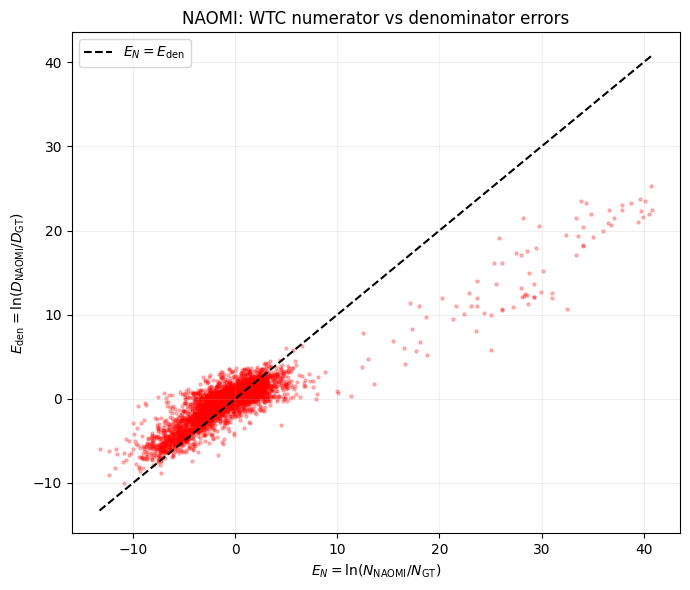

In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt

# Use your existing OUT_DIR
SEED_INDEX = 56

path = os.path.join(
    OUT_DIR,
    f"naomi_wtc_log_terms_seed_{SEED_INDEX:03d}.npz"
)

with np.load(path) as data:
    E_N = data["E_N"]
    E_den = data["E_A"] + data["E_B"]

valid = np.isfinite(E_N) & np.isfinite(E_den)

x = E_N[valid]
y = E_den[valid]

# Randomly sample for readability
rng = np.random.default_rng(42)
idx = rng.choice(len(x), size=min(20000, len(x)), replace=False)

fig, ax = plt.subplots(figsize=(7, 6))

ax.scatter(x[idx], y[idx], c="red", s=5, alpha=0.25)

# Error cancellation line
limits = [
    min(x[idx].min(), y[idx].min()),
    max(x[idx].max(), y[idx].max())
]

ax.plot(limits, limits, "k--", lw=1.5, label=r"$E_N=E_{\mathrm{den}}$")

ax.set_xlabel(r"$E_N=\ln(N_{\mathrm{NAOMI}}/N_{\mathrm{GT}})$")
ax.set_ylabel(r"$E_{\mathrm{den}}=\ln(D_{\mathrm{NAOMI}}/D_{\mathrm{GT}})$")

ax.set_title("NAOMI: WTC numerator vs denominator errors")
ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()